
# Практическая работа № 1
## Настройка окружения и первый notebook

**Дисциплина:** Машинное обучение

**Датасет:** Tips — счета и чаевые в ресторане.

**Цель:** Настроить рабочее окружение, загрузить учебные данные и выполнить их первичный анализ.


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

print("Библиотеки успешно загружены")


Библиотеки успешно загружены


In [2]:

Path("data").mkdir(exist_ok=True)
Path("notebooks").mkdir(exist_ok=True)

df = sns.load_dataset("tips")

df.to_csv("data/tips.csv", index=False)
df = pd.read_csv("data/tips.csv")

print("Датасет успешно загружен")
print("Файл сохранён: data/tips.csv")


Датасет успешно загружен
Файл сохранён: data/tips.csv


In [3]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])
print("Размер таблицы:", df.shape)

Количество строк: 244
Количество столбцов: 7
Размер таблицы: (244, 7)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


In [6]:
print("Количество пропусков в каждом столбце:")
print(df.isnull().sum())

Количество пропусков в каждом столбце:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


In [7]:
df.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [8]:
df.describe(include="object")

,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


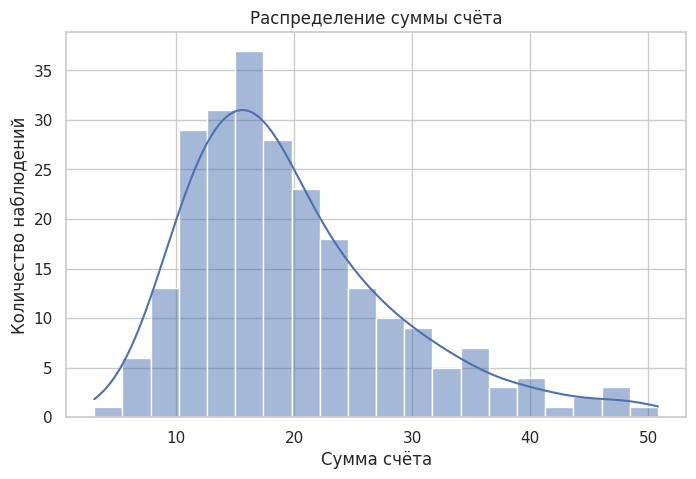

In [9]:

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="total_bill", bins=20, kde=True)

plt.title("Распределение суммы счёта")
plt.xlabel("Сумма счёта")
plt.ylabel("Количество наблюдений")

plt.show()


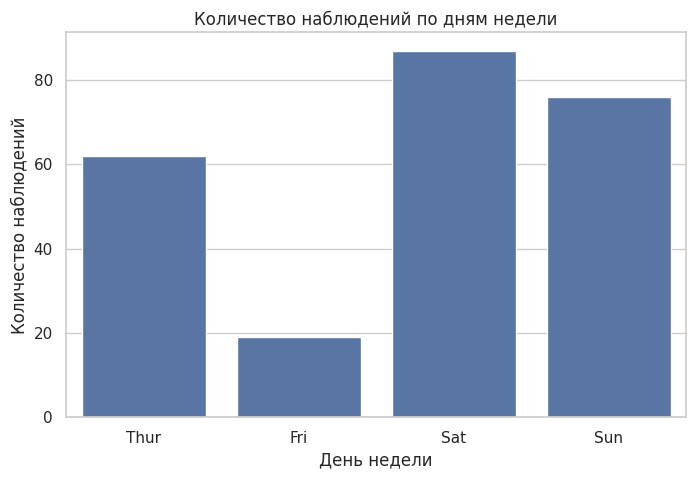

In [10]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="day", order=["Thur", "Fri", "Sat", "Sun"])

plt.title("Количество наблюдений по дням недели")
plt.xlabel("День недели")
plt.ylabel("Количество наблюдений")

plt.show()



## Наблюдения по результатам первичного анализа

1. В датасете представлены наблюдения за четыре дня недели: Thursday, Friday, Saturday и Sunday. Поэтому данные позволяют сравнивать эти дни, но не дают оснований делать выводы о понедельнике, вторнике и остальных днях.

2. Второй график показывает, что количество записей распределено по дням неравномерно. Это означает, что при сравнении поведения посетителей по дням следует учитывать разное количество наблюдений.

3. Гистограмма суммы счёта позволяет увидеть, в каких диапазонах сосредоточена основная часть наблюдений, и проверить, есть ли редкие большие счета. При дальнейшем анализе стоит отдельно исследовать связь суммы счёта с размером чаевых.
